# **Lab 3: Polynomial Regression for Non-Linear Prediction Problems**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

##Q1 : Use the given dataset “Auto MPG” to predict a car’s fuel efficiency (mpg) from its engine horsepower using Polynomial Regression.

**Q1.A :	Read the dataset using the pandas library and inspect it using .head(), .info(), and .describe().**

In [ ]:
df = pd.read_csv('/content/sample_data/auto-mpg.csv');

In [ ]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    object 
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    object 
dtypes: float64(3), int64(4), object(2)
memory usage: 28.1+ KB


In [ ]:
df.describe()

,mpg,cylinders,displacement,weight,acceleration,model year,origin
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,5140.000000,24.800000,82.000000,3.000000


**Q1.B : The horsepower column contains missing values marked as ‘?’. Identify and handle these missing values appropriately, and state which method you used and why.**

In [ ]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model year      0
origin          0
car name        0
dtype: int64


**NO MISSING VALUES

1.   List item
2.   List item


is shown when we do regular isNull ,
as here null values are given as "?"**

> Add blockquote



In [ ]:
print(df["horsepower"].unique())

['130' '165' '150' '140' '198' '220' '215' '225' '190' '170' '160' '95'
 '97' '85' '88' '46' '87' '90' '113' '200' '210' '193' '?' '100' '105'
 '175' '153' '180' '110' '72' '86' '70' '76' '65' '69' '60' '80' '54'
 '208' '155' '112' '92' '145' '137' '158' '167' '94' '107' '230' '49' '75'
 '91' '122' '67' '83' '78' '52' '61' '93' '148' '129' '96' '71' '98' '115'
 '53' '81' '79' '120' '152' '102' '108' '68' '58' '149' '89' '63' '48'
 '66' '139' '103' '125' '133' '138' '135' '142' '77' '62' '132' '84' '64'
 '74' '116' '82']


In [ ]:
print(df["horsepower"].dtype)

object


In [ ]:
print("Missing horsepower values:",
      (df["horsepower"] == "?").sum())

Missing horsepower values: 6


so now we convert those '?' values to NaN values to actually apply dropna on those 6 values out of 398

replacing ? with nan

In [ ]:
df["horsepower"] = df["horsepower"].replace("?", np.nan)

converting it to alphanumeric values

In [ ]:
df["horsepower"] = pd.to_numeric(df["horsepower"])

now check again for null values

In [ ]:
print(df["horsepower"].isnull().sum())

6


now we can apply dropna on that "horsepower" column

In [ ]:
df = df.dropna(subset=["horsepower"])

now we verify again if any null values exist

In [ ]:
print(df["horsepower"].isnull().sum())

0


therefore in Q1.b : we had 6 out of 398 null values , which we converted to NaN and then converted the column itself to aplha numeric values so that we can make our dataframe ready for regression

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 392 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           392 non-null    float64
 1   cylinders     392 non-null    int64  
 2   displacement  392 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        392 non-null    int64  
 5   acceleration  392 non-null    float64
 6   model year    392 non-null    int64  
 7   origin        392 non-null    int64  
 8   car name      392 non-null    object 
dtypes: float64(4), int64(4), object(1)
memory usage: 30.6+ KB


as you can see , 6 rows have been removed , those NaN values

**Q1.C.	Plot horsepower (X) against mpg (Y) and comment on whether the relationship looks linear or curved.**

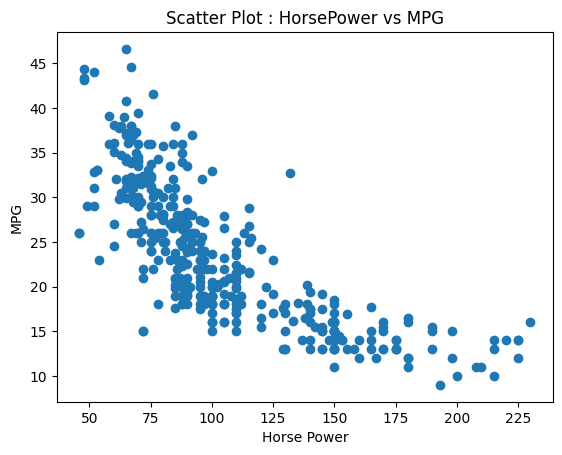

In [ ]:
plt.scatter(df["horsepower"], df["mpg"])
plt.title("Scatter Plot : HorsePower vs MPG")
plt.xlabel("Horse Power")
plt.ylabel("MPG")
plt.show()

With the increase of HorsePower , MPG values is decreasing. so basically the fuel efficiency is decreasing.

Graph is curved downward , so Polynomial regression is applicable.

**Q1.D :	Fit a simple Linear Regression model on horsepower vs mpg. Report its R² and RMSE, and plot the fitted line over the data.**

Still we will try to apply linear regression and observe its best fit line on our data

In [ ]:
X = df[["horsepower"]]
y = df["mpg"]

In [ ]:
linear_model = LinearRegression()

In [ ]:
linear_model.fit(X, y)

LinearRegression()

In [ ]:
# predict y
y_pred = linear_model.predict(X)

In [ ]:
r2 = r2_score(y, y_pred)

rmse = np.sqrt(
    mean_squared_error(y, y_pred)
)

print("R²:", r2)
print("RMSE:", rmse)

R²: 0.6059482578894348
RMSE: 4.893226230065713


now we plot the fitted line for linear regression

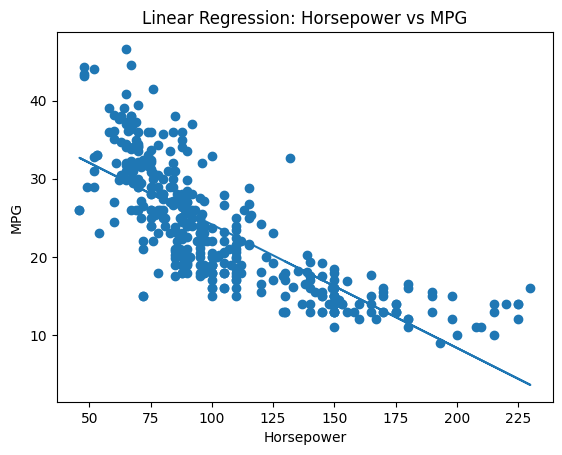

In [ ]:
plt.scatter(
    df["horsepower"],
    df["mpg"]
)

plt.plot(
    df["horsepower"],
    y_pred
)

plt.title("Linear Regression: Horsepower vs MPG")
plt.xlabel("Horsepower")
plt.ylabel("MPG")

plt.show()

A simple straight line correctly shows that higher horsepower means lower gas mileage, but it misses the slight curve in the actual data. Because of this, its predictions are off by about 5 MPG on average. Using a curved line instead would give a much better fit.

simply the decrease is not linear

clearly the decrease is a curve

**Q1.E :	Using sklearn’s PolynomialFeatures, transform horsepower into polynomial features of degree 2, 3, and 4, and fit a Polynomial Regression model (LinearRegression on the transformed features) for each degree.**

In [ ]:
degrees = [2, 3, 4]

models = {}
predictions = {}

for degree in degrees:

    poly = PolynomialFeatures(degree=degree)

    X_poly = poly.fit_transform(X)

    model = LinearRegression()
    model.fit(X_poly, y)

    y_pred_poly = model.predict(X_poly)

    models[degree] = model
    predictions[degree] = y_pred_poly

    print("Degree:", degree)
    print("R²:", r2_score(y, y_pred_poly))
    print("RMSE:", np.sqrt(mean_squared_error(y, y_pred_poly)))
    print()

Degree: 2
R²: 0.6875590305127517
RMSE: 4.3571514671419465

Degree: 3
R²: 0.6882136931259099
RMSE: 4.352584268510596

Degree: 4
R²: 0.6893436054929452
RMSE: 4.344690235778037



**f.	Compare the Linear Regression model and all three polynomial models using R² and RMSE, and plot all fitted curves together with the actual data on a single graph.**

In [ ]:
# calculating R^2 for each model again
linear_pred = linear_model.predict(X)

print("Linear Regression")
print("R²:", r2_score(y, linear_pred))
print("RMSE:", np.sqrt(mean_squared_error(y, linear_pred)))
print()

# Polynomial Regression
for degree in [2, 3, 4]:

    print("Polynomial Regression - Degree", degree)
    print("R²:", r2_score(y, predictions[degree]))
    print("RMSE:", np.sqrt(mean_squared_error(y, predictions[degree])))
    print()

Linear Regression
R²: 0.6059482578894348
RMSE: 4.893226230065713

Polynomial Regression - Degree 2
R²: 0.6875590305127517
RMSE: 4.3571514671419465

Polynomial Regression - Degree 3
R²: 0.6882136931259099
RMSE: 4.352584268510596

Polynomial Regression - Degree 4
R²: 0.6893436054929452
RMSE: 4.344690235778037



lets put all plots together now

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


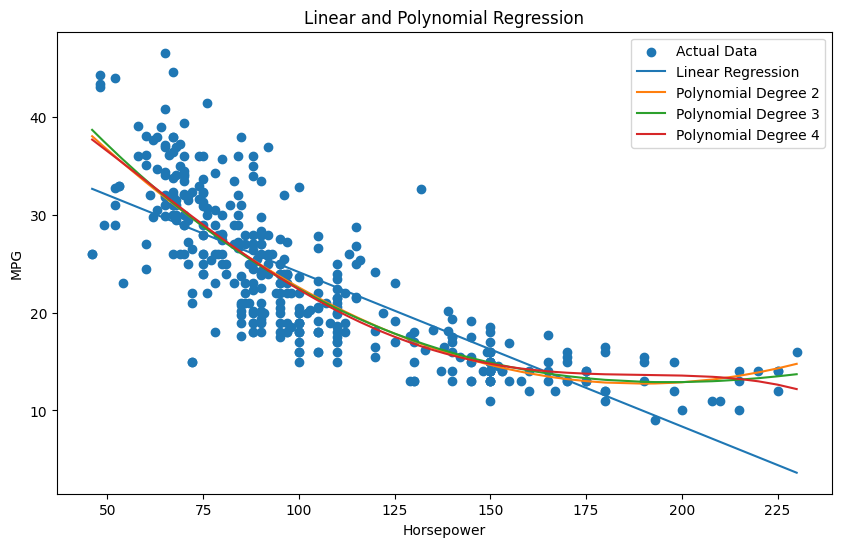

In [ ]:
X_sorted = np.sort(df["horsepower"].values).reshape(-1, 1)

plt.figure(figsize=(10, 6))

# Actual data
plt.scatter(
    df["horsepower"],
    y,
    label="Actual Data"
)

# Linear Regression
linear_sorted_pred = linear_model.predict(X_sorted)

plt.plot(
    X_sorted,
    linear_sorted_pred,
    label="Linear Regression"
)

# Polynomial Regression
for degree in [2, 3, 4]:

    poly = PolynomialFeatures(degree=degree)

    X_sorted_poly = poly.fit_transform(X_sorted)

    poly_pred = models[degree].predict(X_sorted_poly)

    plt.plot(
        X_sorted,
        poly_pred,
        label=f"Polynomial Degree {degree}"
    )

plt.title("Linear and Polynomial Regression")
plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.legend()

plt.show()

Linear Regression gives a straight line, so it cannot fully follow the curved pattern in the data.

Polynomial Regression gives curved lines and follows the actual data more closely.

Degrees 2, 3, and 4 capture the relationship between horsepower and MPG better than the linear model.

As the degree increases, the curve becomes more flexible and can fit the data more closely.

Therefore, Polynomial Regression is more suitable than simple Linear Regression for this dataset because the relationship between horsepower and MPG is non-linear.

Q1.F|

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

train_rmse = []
test_rmse = []

degrees = range(1, 11)

for degree in degrees:

    poly = PolynomialFeatures(degree=degree)

    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()

    model.fit(X_train_poly, y_train)

    train_prediction = model.predict(X_train_poly)
    test_prediction = model.predict(X_test_poly)

    train_error = np.sqrt(
        mean_squared_error(y_train, train_prediction)
    )

    test_error = np.sqrt(
        mean_squared_error(y_test, test_prediction)
    )

    train_rmse.append(train_error)
    test_rmse.append(test_error)

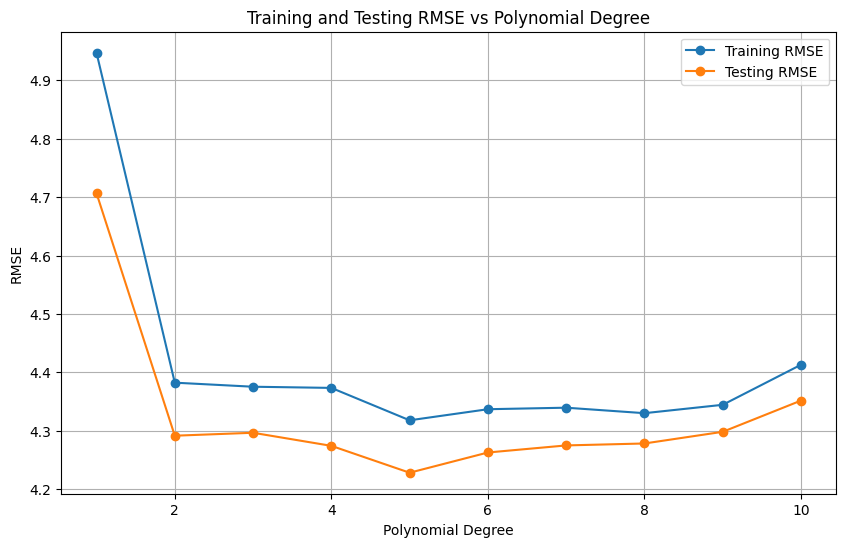

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    degrees,
    train_rmse,
    marker="o",
    label="Training RMSE"
)

plt.plot(
    degrees,
    test_rmse,
    marker="o",
    label="Testing RMSE"
)

plt.xlabel("Polynomial Degree")
plt.ylabel("RMSE")
plt.title("Training and Testing RMSE vs Polynomial Degree")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
for degree, train_error, test_error in zip(
    degrees,
    train_rmse,
    test_rmse
):
    print(
        f"Degree {degree}: "
        f"Training RMSE = {train_error:.2f}, "
        f"Testing RMSE = {test_error:.2f}"
    )

Degree 1: Training RMSE = 4.95, Testing RMSE = 4.71
Degree 2: Training RMSE = 4.38, Testing RMSE = 4.29
Degree 3: Training RMSE = 4.38, Testing RMSE = 4.30
Degree 4: Training RMSE = 4.37, Testing RMSE = 4.27
Degree 5: Training RMSE = 4.32, Testing RMSE = 4.23
Degree 6: Training RMSE = 4.34, Testing RMSE = 4.26
Degree 7: Training RMSE = 4.34, Testing RMSE = 4.27
Degree 8: Training RMSE = 4.33, Testing RMSE = 4.28
Degree 9: Training RMSE = 4.34, Testing RMSE = 4.30
Degree 10: Training RMSE = 4.41, Testing RMSE = 4.35


**Q1.H : Select the Best Polynomial Degree**

In [ ]:
best_degree = degrees[np.argmin(test_rmse)]

print("Best Polynomial Degree:", best_degree)
print("Training RMSE:", train_rmse[best_degree - 1])
print("Testing RMSE:", test_rmse[best_degree - 1])

Best Polynomial Degree: 5
Training RMSE: 4.317873207856326
Testing RMSE: 4.228123417261828


At lower degrees, the model may be underfitting, because it is too simple to capture the curved relationship between horsepower and MPG.

As the degree increases, the model becomes more flexible and the training RMSE decreases.

After a certain degree, the model can become too complex and start fitting the noise in the training data.

This is visible when training RMSE continues decreasing but test RMSE starts increasing.

Therefore, the degree with the lowest test RMSE is selected as the best-performing polynomial model.

In [ ]:
#2.a

X = df[["horsepower", "weight", "displacement"]]
y = df["mpg"]
print(X.head())


   horsepower  weight  displacement
0       130.0    3504         307.0
1       165.0    3693         350.0
2       150.0    3436         318.0
3       150.0    3433         304.0
4       140.0    3449         302.0


In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

print("Correlation Matrix:")
print(X.corr().round(3))

# 2. Add constant for correct VIF calculation
X_with_const = add_constant(X)

# 3. Create a clean VIF DataFrame
vif_df = pd.DataFrame(
    {
        "Feature": X.columns,
        "VIF": [
            variance_inflation_factor(X_with_const.values, i)
            for i in range(1, X_with_const.shape[1])  # Exclude the constant itself
        ],
    }
).sort_values(by="VIF", ascending=False)

print("\nVariance Inflation Factors:")
print(vif_df.to_string(index=False))

Correlation Matrix:
              horsepower  weight  displacement
horsepower         1.000   0.865         0.897
weight             0.865   1.000         0.933
displacement       0.897   0.933         1.000

Variance Inflation Factors:
     Feature       VIF
displacement 10.310539
      weight  7.957383
  horsepower  5.287295


Severe Multicollinearity: Strong pairwise correlations ($r > 0.86$, peaking at $0.933$) cause high redundancy among all three features.Inflated VIF: displacement passes the critical threshold ($\text{VIF} = 10.31$), while weight ($7.96$) and horsepower ($5.29$) also show high inflation

In [ ]:
poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)
poly_model = LinearRegression()
poly_model.fit(X_poly, y)
print("Transformed shape:", X_poly.shape)

Transformed shape: (392, 10)


In [ ]:
feature_names = poly.get_feature_names_out(X.columns)
print("Number of features:", len(feature_names))
print("Features:", list(feature_names))

Number of features: 10
Features: ['1', 'horsepower', 'weight', 'displacement', 'horsepower^2', 'horsepower weight', 'horsepower displacement', 'weight^2', 'weight displacement', 'displacement^2']


In [ ]:
from sklearn.linear_model import Ridge
X_train, X_test, y_train, y_test = train_test_split(X_poly, y, test_size=0.2, random_state=42)
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)
plain = LinearRegression().fit(X_train, y_train)
print("Plain Polynomial Test RMSE:", np.sqrt(mean_squared_error(y_test, plain.predict(X_test))))
print("Ridge Polynomial Test RMSE:", np.sqrt(mean_squared_error(y_test, ridge.predict(X_test))))

Plain Polynomial Test RMSE: 4.049319823967246
Ridge Polynomial Test RMSE: 4.049296011425239


/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=9.63138e-17): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)


In [ ]:
print("Plain model coefficients min/max:", plain.coef_.min(), plain.coef_.max())
print("Ridge model coefficients min/max:", ridge.coef_.min(), ridge.coef_.max())


Plain model coefficients min/max: -0.15159297415998554 0.0024943749188581694
Ridge model coefficients min/max: -0.15155418759728387 0.002492695779563801
